# 06 - Looking inside Vision Transformers

In the previous notebook we saw that accuracy goes down as the object and the background become semantically less related. What is still missing is the reason, or at least one of the reasons, why this happens. Vision Transformers (ViTs) are a great architecture to look into this: they split the image into a grid of patches, and every patch keeps its own token through all blocks of the network. So we can ask, for every patch and every block, which class it currently points to.

We do this with the **logit lens**. We pass each patch token, after each transformer block, through the model’s final LayerNorm and classifier head. This shows which of the 1,000 classes the token would predict at that point in the network.

Running this on all 953,862 composites would be too expensive, so we use the reduced set of 75,000 composites created in notebook 02 instead.

In [ ]:
import os
from pathlib import Path

# Repository paths
REPO_ROOT = Path.cwd()
DATA_DIR = REPO_ROOT / "data"
OUTPUT_DIR = REPO_ROOT / "outputs"
FIG_DIR = OUTPUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
CLASS_INDEX = REPO_ROOT / "helper_files" / "imagenet_class_index.json"
CONSENSUS_PATH = DATA_DIR / "semantic_axes" / "consensus.npy"

# Where the logit-lens results are written
LOGIT_LENS_DIR = OUTPUT_DIR / "logit_lens"

# ImageNet-OOC1k dataset: provided images and metadata in source/, everything we generate in generated/
DATASET_DIR = REPO_ROOT / "ImageNet-OOC1k"
SOURCE_DIR = DATASET_DIR / "source"
GENERATED_DIR = DATASET_DIR / "generated"
COMPOSITES_DIR = GENERATED_DIR / "composites"
SUBSET_PATH = GENERATED_DIR / "mechanism_subset.csv"

# Model weight caches - None keeps the default caches
CACHE_DIR = None
if CACHE_DIR is not None:
    os.environ["HF_HOME"] = str(CACHE_DIR / "hf_cache")
    os.environ["TORCH_HOME"] = str(CACHE_DIR / "torch_cache")

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Inference, analysis and plotting functions live outside the notebook to keep it readable.
from ooc1k.inference.logit_lens import (
    load_logit_lens,
    run_logit_lens,
)
from ooc1k.inference.model_inference import load_class_index
from ooc1k.analysis.patch_competition import (
    get_compactness,
    get_example_predictions,
    get_found_but_lost_aggregation,
    get_object_expansion,
    get_outcome_shares_by_distance,
    get_outcome_shares_by_model,
    get_outcomes,
    get_rank_shares,
    get_realm_balance,
    get_subset_accuracy,
    get_true_class_rank,
    load_logit_lens_results,
    load_subset,
)
from ooc1k.plotting.e_patch_competition import (
    MODEL_LABELS,
    plot_compactness,
    plot_found_but_lost_aggregation,
    plot_mechanism_appendix,
    plot_mechanism_overview,
    plot_expansion_by_model,
    plot_object_expansion,
    plot_outcome_shares,
    plot_patch_evidence,
    plot_realm_balance,
    plot_subset_accuracy,
    plot_true_class_rank,
)

/pfss/mlde/workspaces/mlde_wsp_PI_Roig/bersch/conda/envs/ooc/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Settings

We look at the same five ViTs as in the paper: **ViT-B/16**, our main model, the smaller **ViT-S/16** and larger **ViT-L/16**, **DeiT-B/16** (the same architecture as ViT-B/16, trained on ImageNet-1k with extensive augmentation and regularisation), and **ViT-RelPos-B/16**. The last one has no CLS token. It averages the patch tokens for its prediction. For this model, “CLS prediction” below refers to the prediction from the averaged patch tokens.

`MODEL` selects the ViT for the single-image and competition plots, but the accuracy plot always shows all five. `TAU` is the threshold below which we call a patch undecided.

In [3]:
MODELS = {
    "ViT-B-16": "vit_base_patch16_224.augreg2_in21k_ft_in1k",
    "ViT-S-16": "vit_small_patch16_224.augreg_in21k_ft_in1k",
    "ViT-L-16": "vit_large_patch16_224.augreg_in21k_ft_in1k",
    "DeiT-B-16": "deit_base_patch16_224.fb_in1k",
    "ViT-RelPos-B-16": "vit_relpos_base_patch16_224.sw_in1k",
}
MODEL = "ViT-B-16"          # try any of the models above
TAU = 0.0945                # semantic pull below which a patch is undecided

subset = load_subset(SUBSET_PATH, CLASS_INDEX)
consensus = np.load(CONSENSUS_PATH)
class_labels = [label for _, (_, label) in sorted(load_class_index(CLASS_INDEX).items())]
print(f"{len(subset):,} composites on {subset['background_id'].nunique()} backgrounds in the mechanism subset")

75,000 composites on 260 backgrounds in the mechanism subset


## The logit lens on single composites

Let's look at what the patch tokens would predict at different blocks, using the **logit lens** on a few example composites. To see whether each prediction is more related to the object or the background, we compute its **semantic pull** using the consensus dissimilarity matrix $D$ from notebook 01:

$$
\text{pull} = D(\text{patch class}, \text{background class}) - D(\text{patch class}, \text{object class})
$$

A positive pull (green) means the patch's predicted class is closer to the object class. A negative pull (red) means it is closer to the background class. Values around zero (white) mean the predicted class is at a similar distance from both.

Patches outlined in black predict exactly the object or the background class. Below each heatmap, we show what the CLS token predicts after that block.

The last column, the **realm coverage**, sums this up per block: the share of patches that lean towards the object (pull above a small threshold `TAU`, green), towards the background (pull below `-TAU`, red), or neither (grey).

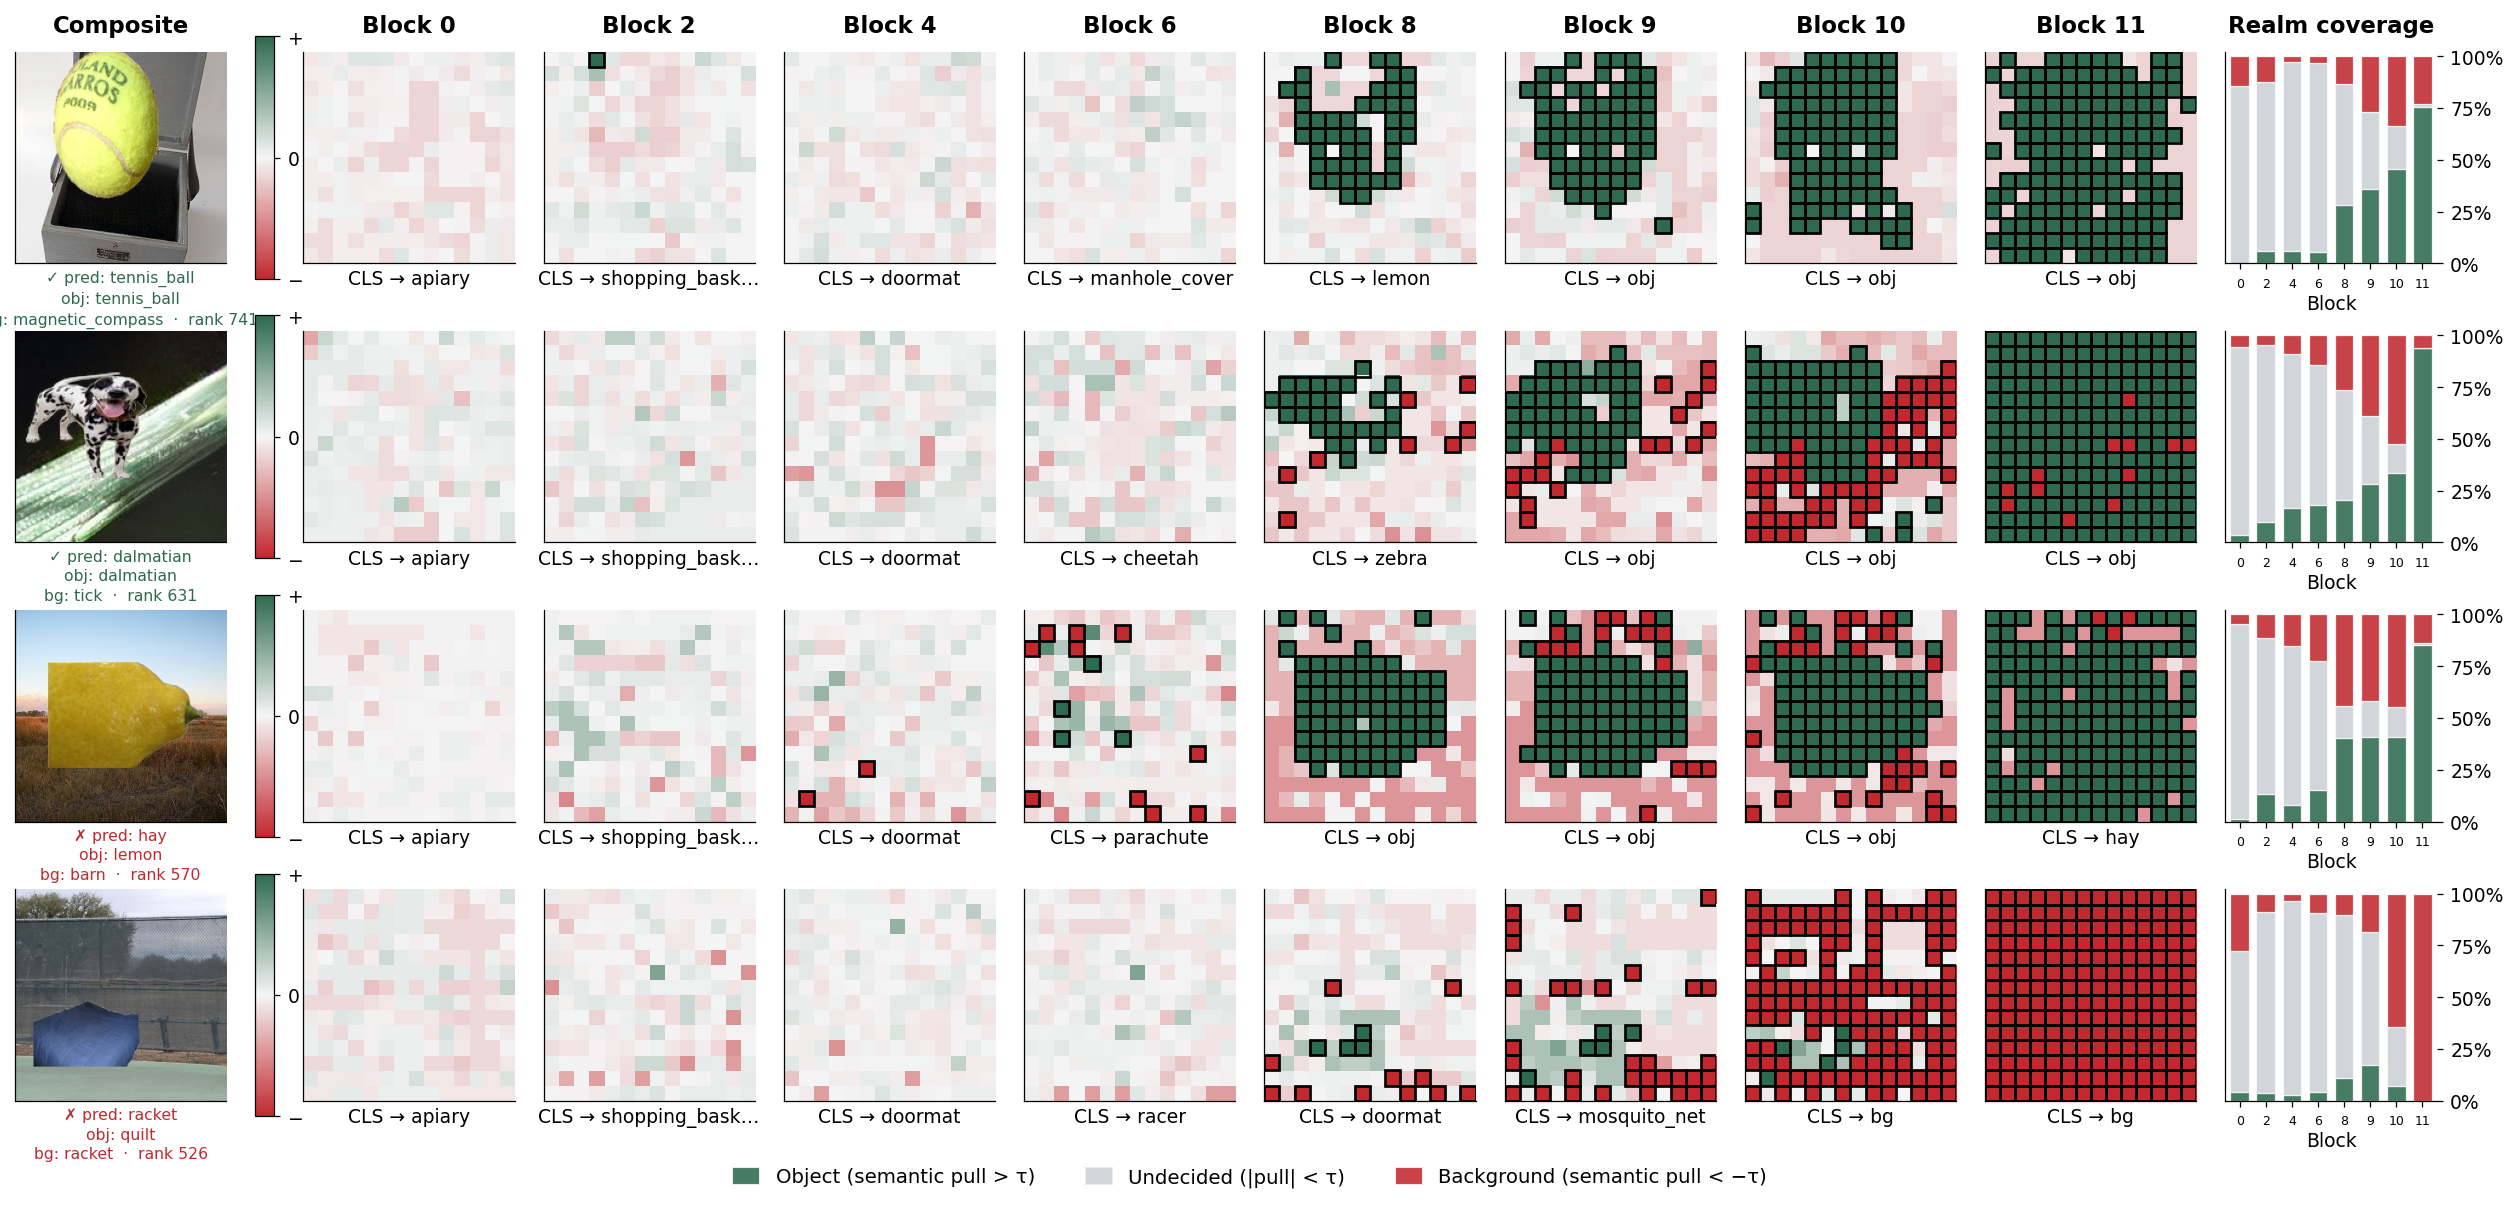

In [4]:
EXAMPLE_COMPOSITES = [
    "ILSVRC2012_val_00048067_with_ILSVRC2012_val_00042309.jpg",  # tennis ball on a magnetic compass background
    "ILSVRC2012_val_00021337_with_ILSVRC2012_val_00041081.jpg",  # dalmatian on a tick background
    "ILSVRC2012_val_00024135_with_ILSVRC2012_val_00007458.jpg",  # lemon on a barn background
    "ILSVRC2012_val_00019000_with_ILSVRC2012_val_00031844.jpg",  # quilt on a tennis racket background
]
LAYERS = [0, 2, 4, 6, 8, 9, 10, 11]   # blocks to show (ViT-L/16 has 24)

lens, transform = load_logit_lens(MODELS[MODEL])
examples = subset.set_index("filename").loc[EXAMPLE_COMPOSITES].reset_index()
example_predictions = get_example_predictions(lens, transform, COMPOSITES_DIR / "composites.h5", examples, consensus)

fig = plot_patch_evidence(example_predictions, class_labels, LAYERS, TAU, show_coverage=True)
fig.savefig(FIG_DIR / "patch_evidence.pdf")
plt.show()

Below you can see the plot as used in the paper. It shows three composites from the full set of composites instead of the mechanism subset, hence we load them from there. The row names (clean win, contested win and found-but-lost) are the outcome types we define further down.

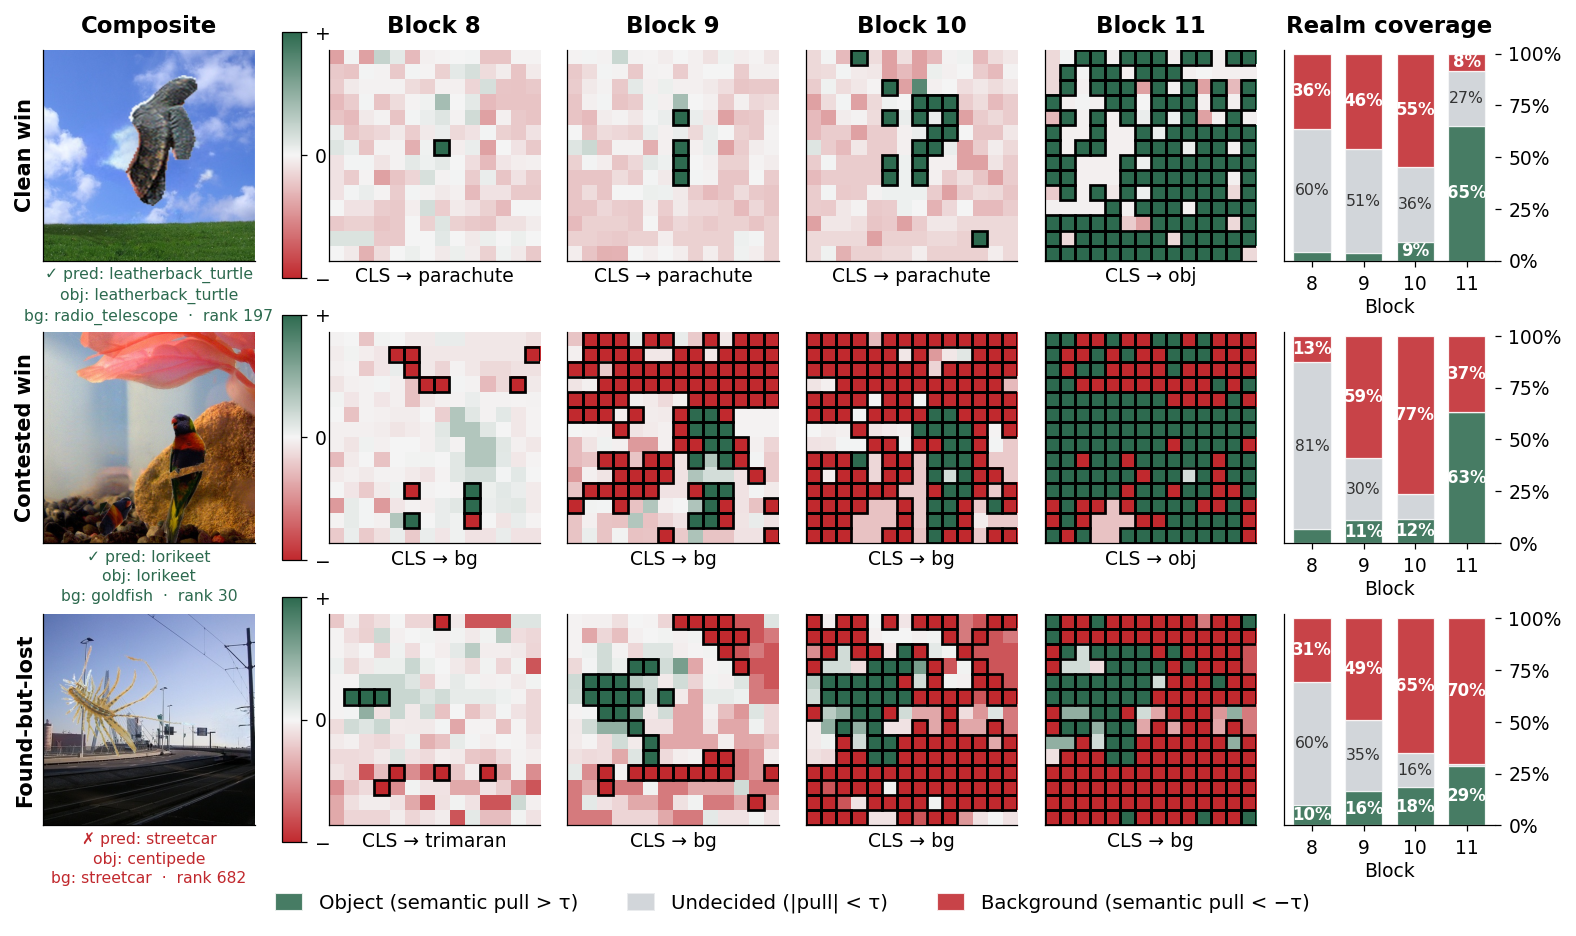

In [5]:
PAPER_COMPOSITES = [
    "ILSVRC2012_val_00014018_with_ILSVRC2012_val_00016779.jpg",  # clean win
    "ILSVRC2012_val_00020785_with_ILSVRC2012_val_00046356.jpg",  # contested win
    "ILSVRC2012_val_00024820_with_ILSVRC2012_val_00004841.jpg",  # found-but-lost
]
PAPER_LAYERS = [8, 9, 10, 11]

# The rows of the composite metadata follow composites.h5, so the row number is the position in the H5 file.
composites = load_subset(COMPOSITES_DIR / "metadata.csv", CLASS_INDEX).rename_axis("h5_index").reset_index()
paper_examples = composites.set_index("filename").loc[PAPER_COMPOSITES].reset_index()
paper_predictions = get_example_predictions(lens, transform, COMPOSITES_DIR / "composites.h5", paper_examples, consensus)

fig = plot_patch_evidence(paper_predictions, class_labels, PAPER_LAYERS, TAU, row_labels=["Clean win", "Contested win", "Found-but-lost"])
fig.savefig(FIG_DIR / "patch_evidence_paper.pdf")
plt.show()

## Running the logit lens on the whole subset

Next, we look at how patch predictions change across blocks for all 75,000 composites in the mechanism subset. For each model, we save:

- the predicted class of every patch after every block (composites × blocks × patches),
- the CLS prediction after every block,
- and the final CLS logits, which we use below to see where the true class ranks, and in notebook 07 to re-rank the predictions.

In [6]:
BATCH_SIZE = 128
NUM_WORKERS = 8
SKIP_EXISTING = True

run_logit_lens(
    models=MODELS,
    subset_path=SUBSET_PATH,
    composites_h5=COMPOSITES_DIR / "composites.h5",
    originals_dir=SOURCE_DIR / "originals",
    class_index_path=CLASS_INDEX,
    output_dir=LOGIT_LENS_DIR,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    skip_existing=SKIP_EXISTING,
)

print(f"Saved to {LOGIT_LENS_DIR}")

ViT-B-16: ViT-B-16_logit_lens.h5 exists, skipped
ViT-S-16: ViT-S-16_logit_lens.h5 exists, skipped
ViT-L-16: ViT-L-16_logit_lens.h5 exists, skipped
DeiT-B-16: DeiT-B-16_logit_lens.h5 exists, skipped
ViT-RelPos-B-16: ViT-RelPos-B-16_logit_lens.h5 exists, skipped
Saved to /pfss/mlde/workspaces/mlde_wsp_PI_Roig/bersch/repositories/OOC-Dataset-Creator/imagenet-ooc1k/outputs/logit_lens


## Accuracy along the semantic axis, again

As a sanity check, let's see whether accuracy still declines with semantic distance in our subset. We group the composites into the same 20 bins of 50 ranks used to select the subset and compute each model's accuracy in every bin.

The decline is still there, although the curves are a bit noisier.

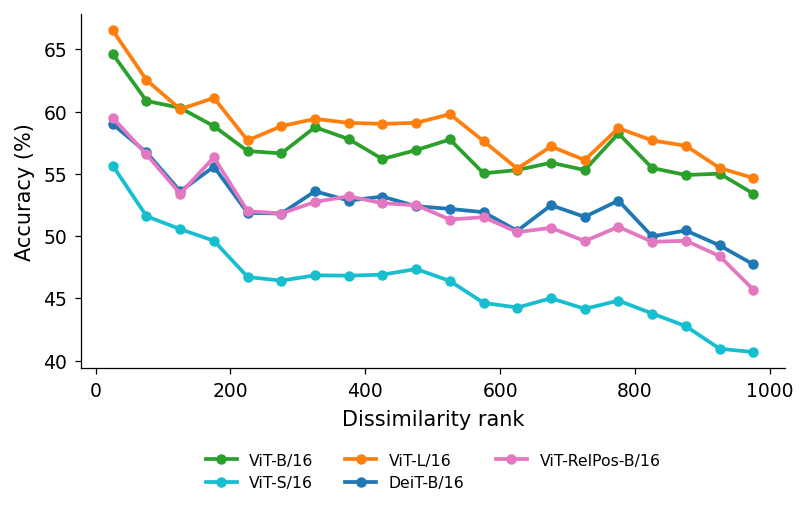

ViT-B-16           57.2
ViT-S-16           46.3
ViT-L-16           58.7
DeiT-B-16          52.5
ViT-RelPos-B-16    51.9
dtype: float64

In [7]:
results = {model: load_logit_lens_results(LOGIT_LENS_DIR / f"{model}_logit_lens.h5", subset) for model in MODELS}
curves = get_subset_accuracy(results, subset, bin_width=50)

fig = plot_subset_accuracy(curves)
fig.savefig(FIG_DIR / "subset_accuracy.pdf")
plt.show()

# Top-1 accuracy on the whole subset, in percent
pd.Series({model: 100 * result["composites"]["correct"].mean() for model, result in results.items()}).round(1)

## How do these patterns evolve?

Looking at the patch predictions, we identified four **high-level outcome types**. They describe how the object evidence across patches relates to the final prediction. More detailed patterns may exist within each type, but these are the categories we use in the paper.

We classify each composite using its final prediction, the number of patches that predict exactly the object class, and the **realm balance**. Realm balance measures the share of decided patches that favour the object:

$$
\text{Realm balance}
=
\frac{N_{\text{object realm}}}
{N_{\text{object realm}} + N_{\text{background realm}}}
$$

The two counts come from the object and background realms defined by semantic pull. Undecided patches are excluded. These realms include predictions of semantically related classes, while the detection threshold below counts exact matches to the object class.

Using the patch predictions at the end of the network, we define:

- **Clean win**: the final prediction is correct, at least 20 patches predict exactly the object class, and realm balance is above 75%.
- **Contested win**: the final prediction is correct, but the composite does not qualify as a clean win.
- **Found-but-lost**: the final prediction is wrong, although at least 20 patches predict exactly the object class.
- **No detection**: the final prediction is wrong, and fewer than 20 patches predict exactly the object class.

The 20-patch threshold keeps 98.9% of the correctly classified composites as detected. The plot below shows how often each outcome occurs for the five ViTs, with accuracy given by the combined share of clean and contested wins.

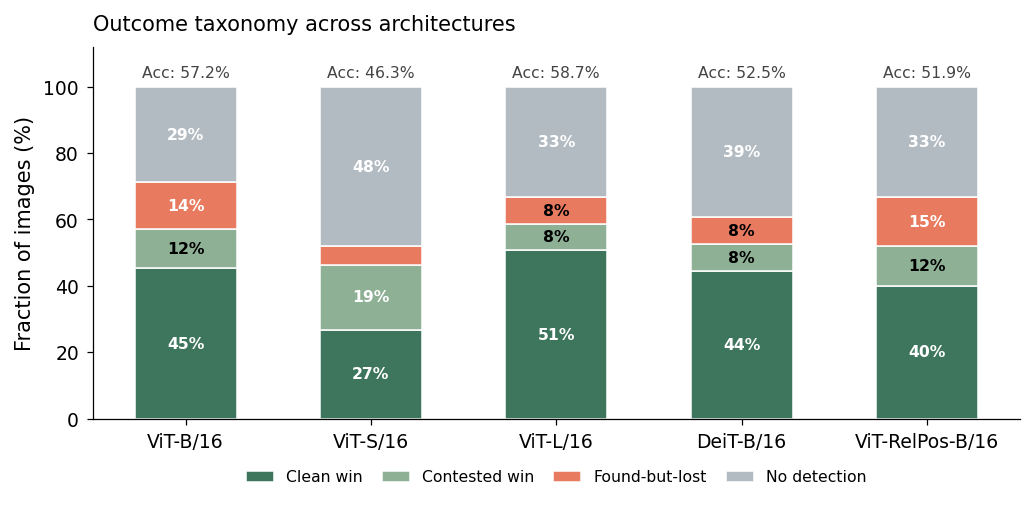

outcome,Clean win,Contested win,Found-but-lost,No detection
ViT-B-16,45.3,11.9,14.1,28.7
ViT-S-16,26.8,19.5,5.7,47.9
ViT-L-16,50.7,8.0,8.2,33.2
DeiT-B-16,44.3,8.1,8.3,39.2
ViT-RelPos-B-16,40.1,11.9,14.9,33.2


In [8]:
MIN_OBJECT_PATCHES = 20     # exact object patches needed to count as detected
CLEAN_BALANCE = 0.75        # realm balance above which a correct composite is a clean win

outcomes = {
    model: get_outcomes(results[model], subset, consensus, TAU, min_object_patches=MIN_OBJECT_PATCHES, clean_balance=CLEAN_BALANCE)
    for model in MODELS
}
shares = get_outcome_shares_by_model(outcomes)

fig = plot_outcome_shares(shares, labels=MODEL_LABELS, title="Outcome taxonomy across architectures")
fig.savefig(FIG_DIR / "outcome_shares.pdf")
plt.show()

# Share of every outcome type, in percent
(100 * shares).round(1)

### Outcomes and semantic distance

Now we want to understand how these outcome types change with semantic distance. For that, we split the composites into three groups: low (ranks 1-350), mid (351-700) and high (701-1,000) distance. This is done for the model that has been selected at the top.


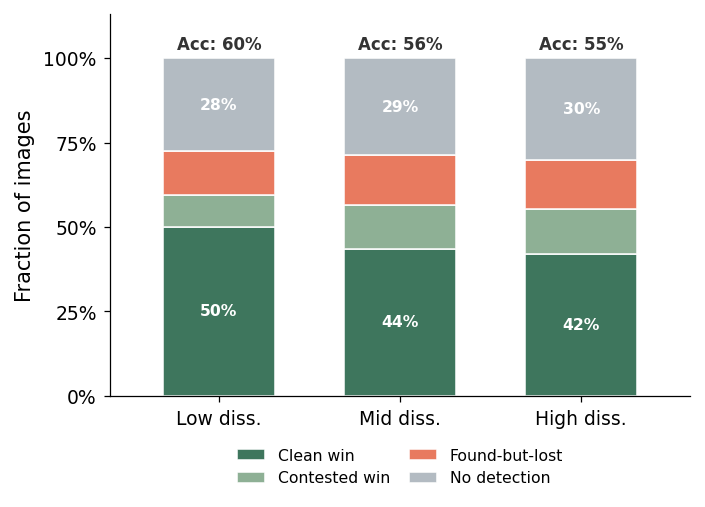

outcome,Clean win,Contested win,Found-but-lost,No detection
distance,,,,
Low,50.1,9.5,12.9,27.5
Mid,43.6,12.8,14.8,28.8
High,41.9,13.5,14.5,30.1


In [9]:
distance_shares = get_outcome_shares_by_distance(outcomes[MODEL], subset)

fig = plot_outcome_shares(distance_shares, labels={"Low": "Low diss.", "Mid": "Mid diss.", "High": "High diss."}, detailed=False)
fig.savefig(FIG_DIR / "outcome_shares_by_distance.pdf")
plt.show()

# Share of every outcome type, in percent
(100 * distance_shares).round(1)

### Objects and backgrounds compete across blocks

The four outcome types above are based on the last block only. To see how the competition develops, we follow the **realm balance** across all blocks, now for groups of composites. A balance of 50% means that object and background have an equal share of the decided patches.

We group composites by whether the final prediction is correct (solid lines) or incorrect (dashed lines), and by semantic distance: low (ranks 1–350), mid (351–700) and high (701–1,000). The grey line shows correctly classified original images. Since these have no background class, we use the nearest other class on the semantic axis as the competitor.

Correctly classified composites shift clearly towards the object in the last block, while incorrectly classified ones barely reach a tie. The curves also separate by semantic distance: the less related the object and background are, the lower the realm balance.

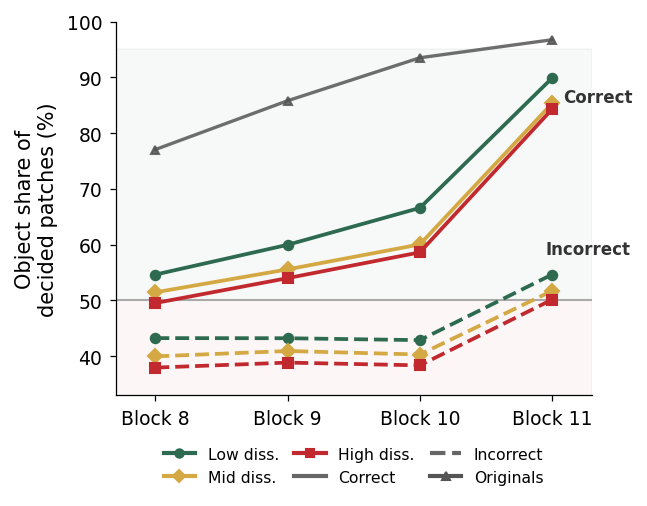

Correct             Incorrect             Originals
          Low   Mid  High       Low   Mid  High          
block                                                    
8        54.6  51.4  49.5      43.2  39.9  37.9      77.0
9        60.0  55.6  54.0      43.2  40.9  38.8      85.8
10       66.6  60.0  58.6      42.9  40.3  38.3      93.5
11       89.9  85.3  84.3      54.6  51.7  50.1      96.7

In [10]:
BLOCKS = [8, 9, 10, 11]     # the last four blocks of ViT-B/16; use 20 to 23 for ViT-L/16

balance = get_realm_balance(results[MODEL], subset, consensus, TAU, BLOCKS)

fig = plot_realm_balance(balance)
fig.savefig(FIG_DIR / "realm_balance.pdf")
plt.show()

# Object share of the decided patches, in percent
(100 * balance).round(1)

### How far does the object spread?

The previous plot separated correct and incorrect composites. Now we split them into the four outcome types and count how many patches predict exactly the object class after each block.

This lets us see when the object class appears in the patch predictions and how widely it spreads across patches for each outcome.

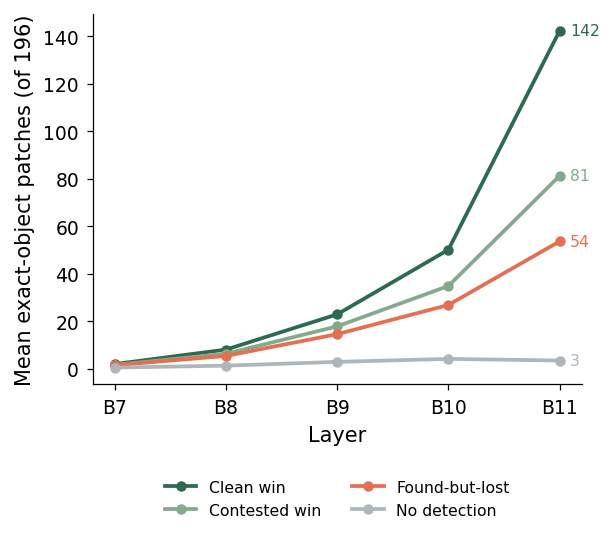

outcome,Clean win,Contested win,Found-but-lost,No detection
block,,,,
7,2.0,1.6,1.5,0.5
8,8.1,6.3,5.4,1.3
9,22.9,17.9,14.6,2.9
10,50.1,34.9,26.9,4.2
11,142.3,81.2,53.6,3.5


In [11]:
BLOCKS = [7, 8, 9, 10, 11]  # the last five blocks of ViT-B/16; use 19 to 23 for ViT-L/16

expansion = get_object_expansion(results[MODEL], subset, outcomes[MODEL], BLOCKS)

fig = plot_object_expansion(expansion)
fig.savefig(FIG_DIR / "object_expansion.pdf")
plt.show()

# Mean number of exact object patches
expansion.round(1)

## Found but lost: the object is there, the decision is not

The most interesting cases are the found-but-lost composites, where patches predict the object class but the final decision goes to another class. Let's examine these cases more closely:

1. What does the CLS token predict across blocks?
2. How close does it get to the correct class?
3. How is the object evidence arranged on the patch grid?

These analyses will also be useful in notebook 07, where we try to correct these errors post hoc.


### Patches say object, the CLS token does not (FBL only)

We first look at the CLS predictions across the final blocks, for found-but-lost composites only. To measure how semantically close each prediction is to the object class, we use **classification proximity**:

$$
\text{Classification proximity}
= 1 - D(\text{CLS prediction}, \text{object class})
$$

It is 100% when the CLS token predicts the object class and decreases as its prediction becomes less related to the object. The red line shows this proximity, while the green line shows the realm balance of the patches.

Until block 10, the CLS prediction and the patches move towards the object together. In the last block, they split: the patches move further towards the object, while the CLS prediction moves away from it.

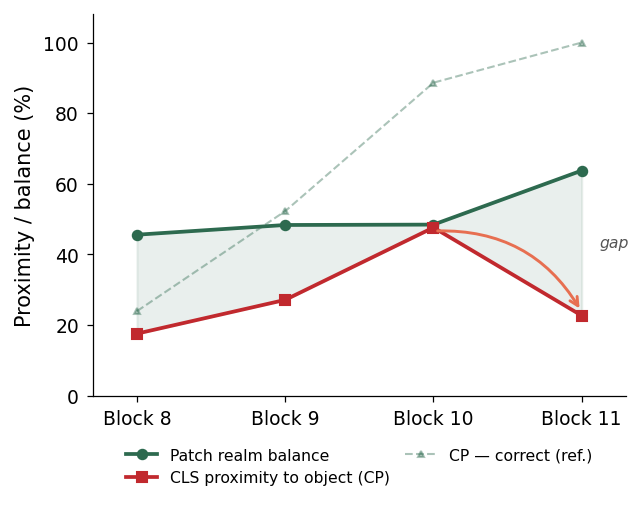

,Realm balance,CLS proximity,CLS proximity (correct)
block,,,
8,45.6,17.6,24.0
9,48.3,27.1,52.3
10,48.4,47.6,88.6
11,63.7,22.7,100.0


In [12]:
BLOCKS = [8, 9, 10, 11]     # the last four blocks of ViT-B/16; use 20 to 23 for ViT-L/16

aggregation = get_found_but_lost_aggregation(results[MODEL], subset, outcomes[MODEL], consensus, TAU, BLOCKS)

fig = plot_found_but_lost_aggregation(aggregation)
fig.savefig(FIG_DIR / "found_but_lost_aggregation.pdf")
plt.show()

# Realm balance and classification proximity, in percent
(100 * aggregation).round(1)

### Where does the correct class rank?

Next, we look at where the object class ranks in the final CLS logits for each composite. This tells us how highly the model ranks the correct answer, even when it selects another class.

For found-but-lost cases, the object class is still almost always in the top 5, with a median of 2. So the correct class is usually the runner-up.

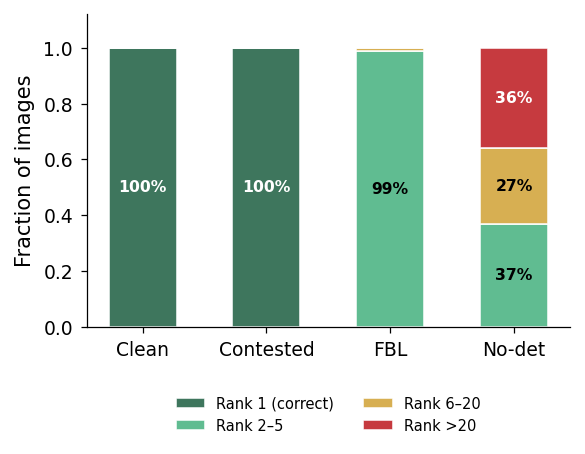

outcome
Clean win         1.0
Contested win     1.0
Found-but-lost    2.0
No detection      9.0
Name: rank, dtype: float64

In [13]:
ranks = get_true_class_rank(results[MODEL], subset)
rank_shares = get_rank_shares(ranks, outcomes[MODEL])

fig = plot_true_class_rank(rank_shares)
fig.savefig(FIG_DIR / "true_class_rank.pdf")
plt.show()

# Median rank of the object class
ranks.groupby(outcomes[MODEL], observed=False).median()

### The object stays compact

Now we know that patches still predict the object class in found-but-lost cases, and that it almost always stays in the top 5 even when the CLS token picks another class. Looking at the examples above, these patches also seem to form a cluster. So let's see how this differs across the four outcome types.

For each block, we look at the patches that predict the final CLS token's top-ranked class or its runner-up. For each class, we measure how far these patches are from their centre on average, to see how compact or spread out they are.

In found-but-lost composites, the runner-up (usually the object) is the more compact class in about 80% of cases at blocks 9 and 10, while the wrongly predicted class is more spread out. Clean wins show the opposite: the correctly predicted class is more compact. This fits the picture from above: the object is found by a compact group of patches, but the final decision still goes to another class.

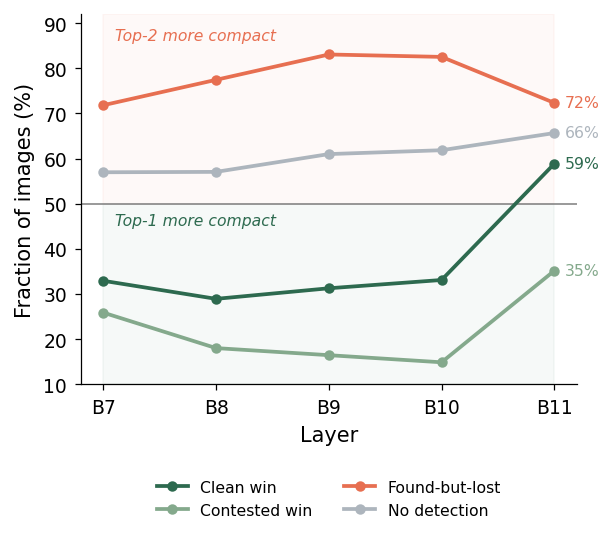

outcome,Clean win,Contested win,Found-but-lost,No detection
block,,,,
7,32.9,25.9,71.8,57.0
8,28.9,18.0,77.4,57.1
9,31.3,16.5,83.1,61.0
10,33.1,14.9,82.5,61.9
11,58.9,35.2,72.3,65.7


In [14]:
BLOCKS = [7, 8, 9, 10, 11]  # the last five blocks of ViT-B/16; use 19 to 23 for ViT-L/16

compactness = get_compactness(results[MODEL], outcomes[MODEL], BLOCKS)

fig = plot_compactness(compactness)
fig.savefig(FIG_DIR / "compactness.pdf")
plt.show()

# Share of composites where the runner-up is more compact, in percent
(100 * compactness).round(1)

## Putting it together

The figures for the paper combine the plots above for `MODEL`. The first one sums up the main story: (a) found-but-lost and no-detection cases grow with semantic distance, (b) objects and backgrounds compete for the patches across the last blocks, and (c) in found-but-lost cases the patches still favour the object while the CLS token turns away from it.

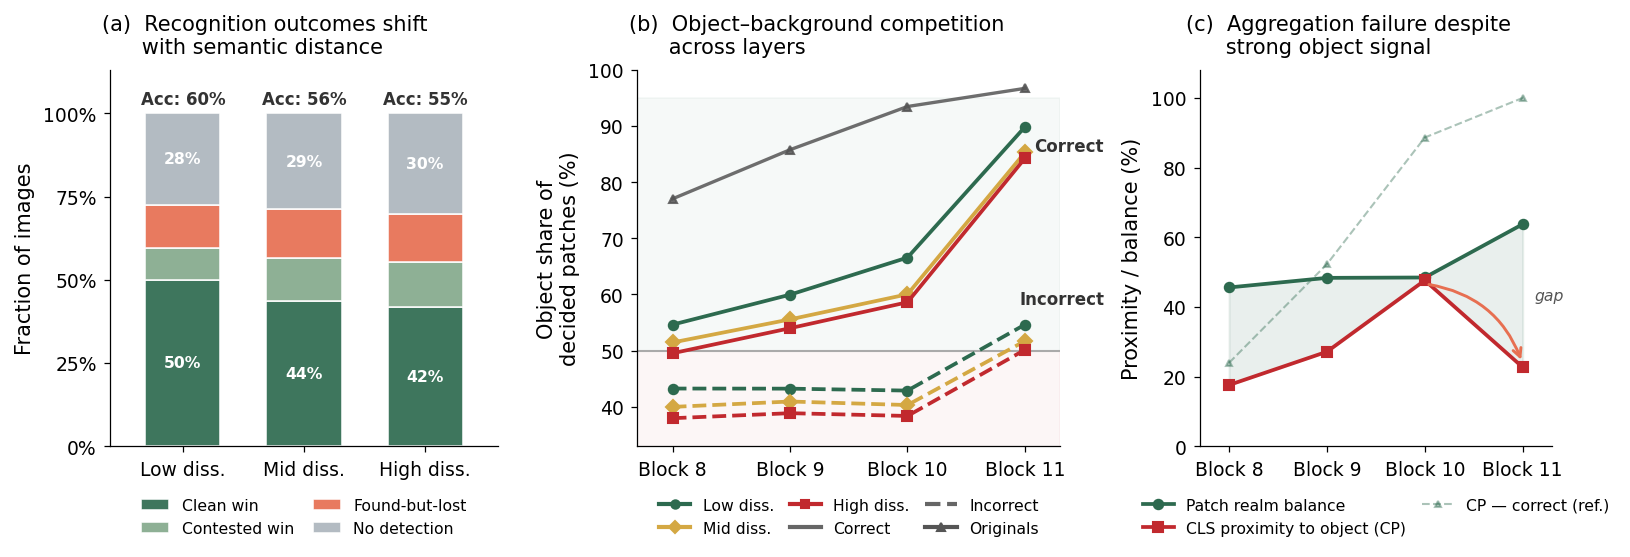

In [15]:
fig = plot_mechanism_overview(distance_shares, balance, aggregation)
fig.savefig(FIG_DIR / "mechanism_overview.pdf")
plt.show()

The second one, for the appendix, collects the details of the found-but-lost cases: (a) the correct class is almost always among the top five, (b) the object keeps spreading over the patches, and (c) the runner-up class is usually more compact than the prediction.

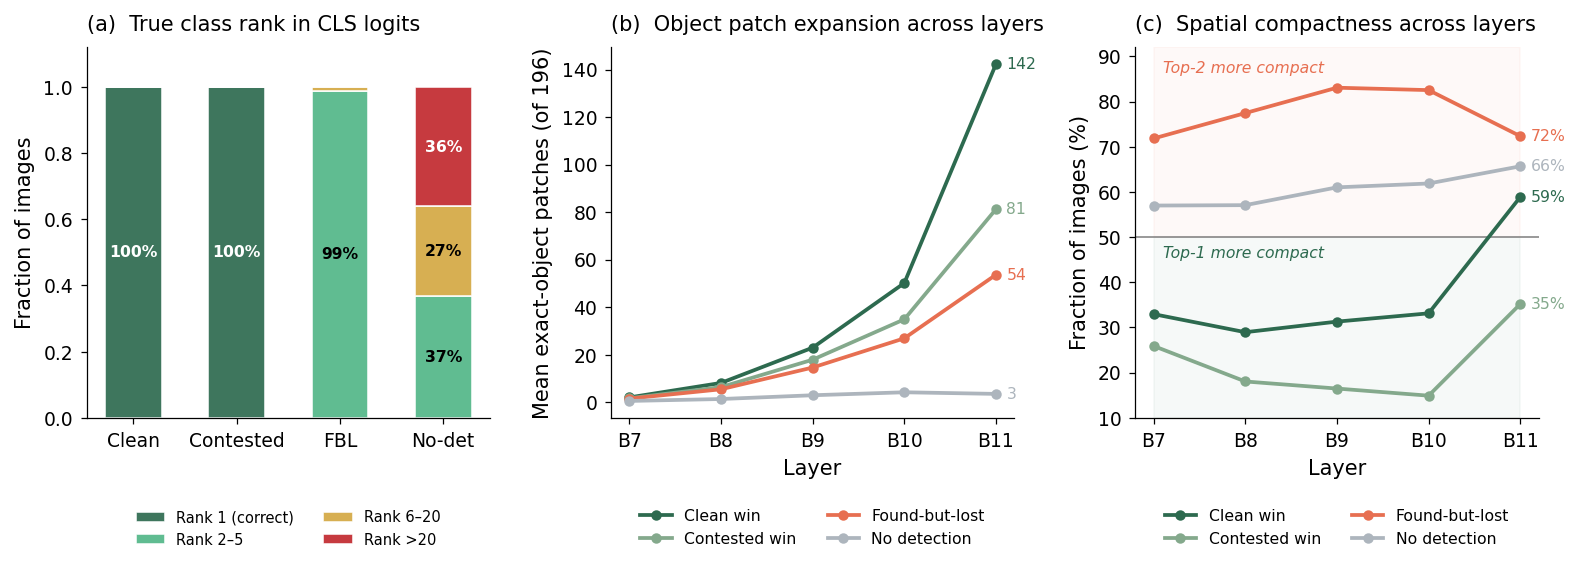

In [16]:
fig = plot_mechanism_appendix(rank_shares, expansion, compactness)
fig.savefig(FIG_DIR / "mechanism_appendix.pdf")
plt.show()

For the comparison across architectures in the appendix, the outcome types of all five ViTs are the figure `outcome_shares.pdf` from above. The object patch expansion of all five ViTs goes into one row, each over its own last five blocks (blocks 19 to 23 for ViT-L/16).

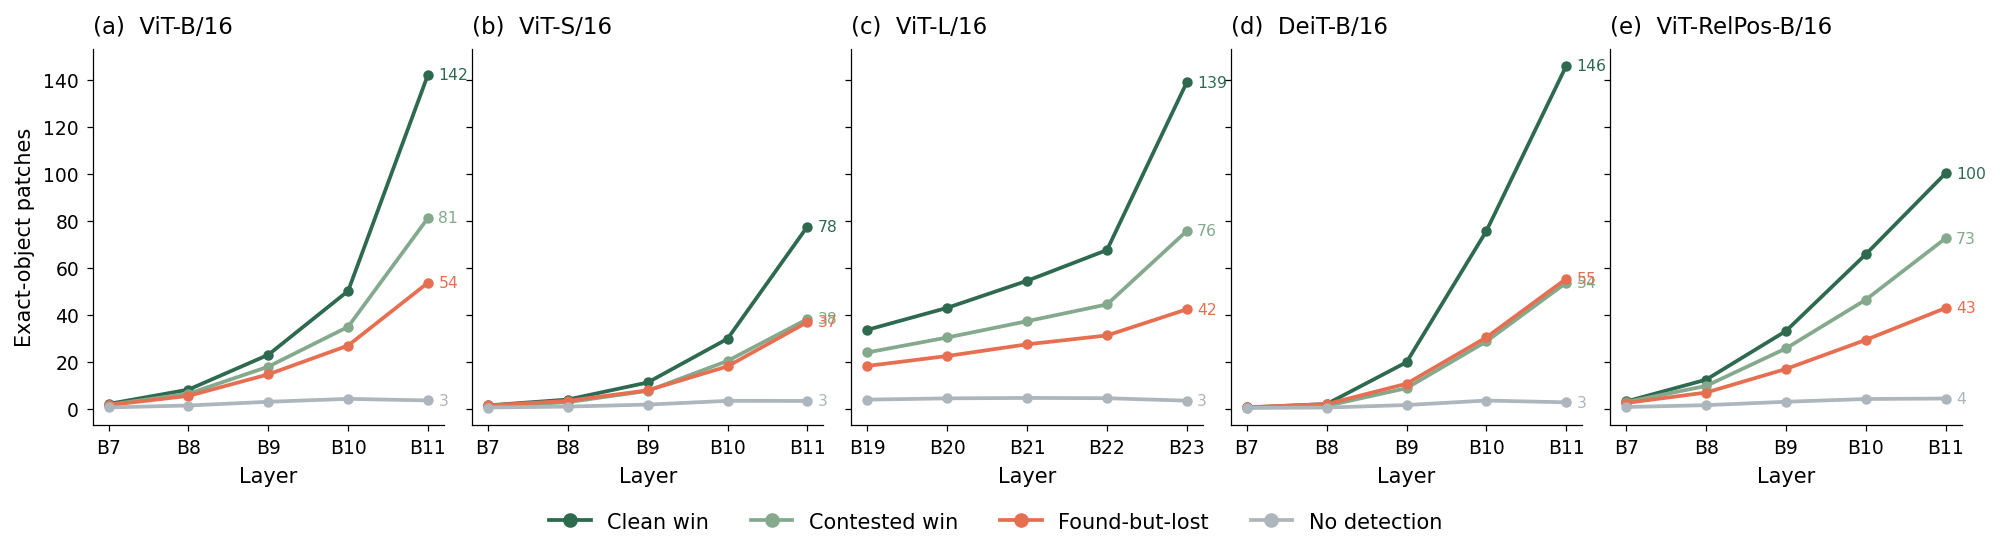

In [17]:
expansions = {}
for model in MODELS:
    n_blocks = results[model]["composites"]["patch_predictions"].shape[1]
    expansions[model] = get_object_expansion(results[model], subset, outcomes[model], list(range(n_blocks - 5, n_blocks)))

fig = plot_expansion_by_model(expansions)
fig.savefig(FIG_DIR / "object_expansion_all_models.pdf")
plt.show()